### Tasks:

1. Remember: scale your data appropriately

2. Decide on a testing strategy (a simple test/train split? a CV strategy? set a test set aside to be looked at at the very end?)

2. Decide your optimization metric.

3. Write down your network architecture. You can start from a fully connected, multi-layer perceptron (and then explore)

4. Use one the package among those we've seen. These include Tensorflow via keras, pytorch, and the MPL classifier implemented in scikit-learn. This is an opportunity to pick the one you're most interested in learning. 

5. Optimize the hyperparameters of your network. Explore different hyperparameters and see what fits the data best.  Do your best now to optimize the network architecture. Be creative!

6. Report on the perfomance of the network on the test set; report other metrics that have not been optimized.

- **1. Galaxies vs quasars (but with neural networks)** Go back to our SDSS data we've used in Lecture 19. We had color differences, and the task was to classifty quasars vs galaxies. Repeat that task with a neural network.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

file = pd.read_csv("C:/Users/user/Desktop/astrostatistics_bicocca_2026/solutions/galaxyquasar.csv")
colors = ['u-g', 'g-r', 'r-i', 'i-z']
for c in colors:
    a, b = c.split('-')
    file[c] = file[a] - file[b]
X = file[colors].values
y = (file['class'] == 'QSO').astype(int).values
print(X.shape, y.mean())

(50000, 4) 0.14268


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)    # il test si guarda solo alla fine

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

In [3]:
from sklearn.neural_network import MLPClassifier
clf = MLPClassifier(hidden_layer_sizes=(16, 16), activation='relu', solver='adam',
                    alpha=1e-4, learning_rate_init=1e-3, max_iter=300,
                    early_stopping=True, random_state=0)
clf.fit(X_train_s, y_train)
print("train accuracy:", clf.score(X_train_s, y_train))

train accuracy: 0.985575


In [4]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'hidden_layer_sizes': [(8,), (16,), (32,), (16, 16), (32, 32), (64, 32, 16)],
    'alpha': [1e-5, 1e-4, 1e-3, 1e-2],
    'learning_rate_init': [1e-3, 1e-2],
    'activation': ['relu', 'tanh'],
}
gscv = GridSearchCV(
    MLPClassifier(solver='adam', max_iter=300, early_stopping=True, random_state=0),
    param_grid, scoring='roc_auc', cv=5, n_jobs=-1, verbose=1)

# se è troppo lento: lancia solo su un sottoinsieme del training, ad es. 20 000 punti
n = min(20000, len(X_train_s))
gscv.fit(X_train_s[:n], y_train[:n])
print("best params:", gscv.best_params_)
print("best CV AUC:", gscv.best_score_)

Fitting 5 folds for each of 96 candidates, totalling 480 fits
best params: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (32, 32), 'learning_rate_init': 0.01}
best CV AUC: 0.992451434527748


In [5]:
best = MLPClassifier(solver='adam', max_iter=500, early_stopping=True,
                     random_state=0, **gscv.best_params_)
best.fit(X_train_s, y_train)
print("train accuracy:", best.score(X_train_s, y_train))

train accuracy: 0.9875


AUC: 0.9920834882677491
accuracy: 0.9844
completeness: 0.928521373510862
contamination: 0.03915881073241479
              precision    recall  f1-score   support

      GALAXY       0.99      0.99      0.99      8573
         QSO       0.96      0.93      0.94      1427

    accuracy                           0.98     10000
   macro avg       0.97      0.96      0.97     10000
weighted avg       0.98      0.98      0.98     10000



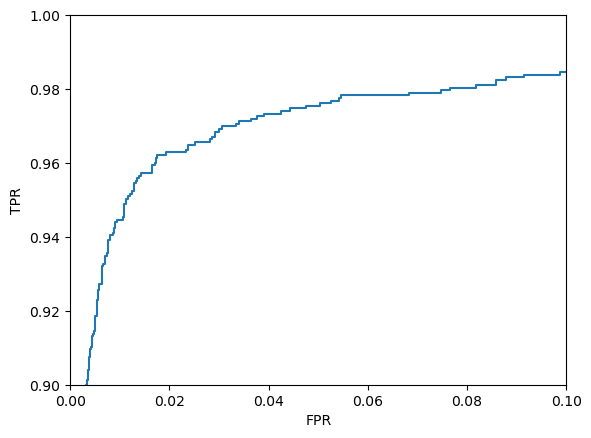

In [6]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report

p = best.predict_proba(X_test_s)[:, 1]
y_pred = best.predict(X_test_s)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("AUC:", roc_auc_score(y_test, p))
print("accuracy:", (tp + tn) / len(y_test))
print("completeness:", tp / (tp + fn))
print("contamination:", fp / (tp + fp))
print(classification_report(y_test, y_pred, target_names=['GALAXY', 'QSO']))

fpr, tpr, _ = roc_curve(y_test, p)
plt.plot(fpr, tpr); plt.xlim(0, 0.1); plt.ylim(0.9, 1)
plt.xlabel('FPR'); plt.ylabel('TPR');

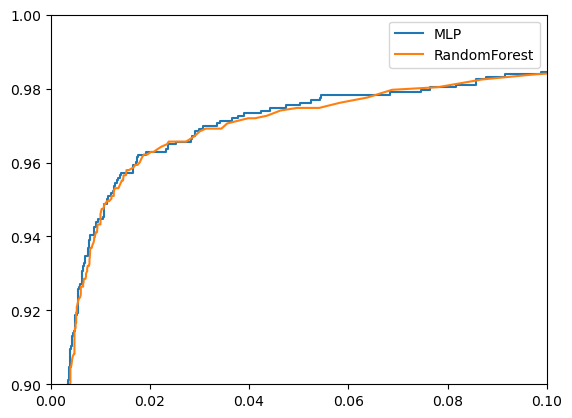

In [7]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0).fit(X_train, y_train)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf.predict_proba(X_test)[:, 1])
plt.plot(fpr, tpr, label='MLP'); plt.plot(fpr_rf, tpr_rf, label='RandomForest')
plt.xlim(0, 0.1); plt.ylim(0.9, 1); plt.legend();